# The Max-Cut Problem
# 1️⃣ What is Max-Cut? <br>
The Max-Cut problem is a well-known combinatorial optimization problem from graph theory. <br>
Goal:
Given a graph 𝐺=(𝑉,𝐸) divide its nodes 𝑉 into two groups (a “cut”) so that the number 
(or total weight) of edges between the two groups is as large as possible.
Each edge that connects nodes in different groups is said to be “cut” by the partition.

In [1]:
#Libraries
import dimod
import networkx as nx
import matplotlib.pyplot as plt
from dwave.samplers import SimulatedAnnealingSampler

#  2️⃣ Simple Example

Imagine 4 nodes arranged in a square (our example graph): <br>
`0 — 1` <br>
`|   |` <br>
`3 — 2` <br>
We can assign each node to one of two groups, represented by binary variables: <br>
$x_{i} = 0$ node i in group A <br>
$x_{i} = 1$  node i in group B <br>
Now, each edge  (i,j) contributes 1 to the cut if 
$x_{i} \neq x_{j}$
, and 0 otherwise. <br>
The goal: <br>
Find assignments
$x \in \{0,1\} $
, that maximize the number of edges with different endpoints.

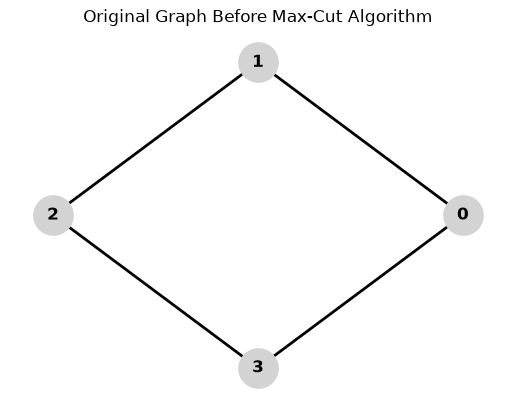

In [3]:
# ---- 1) Define a simple graph -----------------------------------------------
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]
nodes = {u for e in edges for u in e}

# ---- 1.1) Define the graph fr representation ---------------------------------

G = nx.Graph()
G.add_edges_from(edges)

# ---- 1.2) Choose a layout (circular looks nice for 4 nodes) --------------------
pos = nx.circular_layout(G)

# ---- 1.3) Draw the graph -------------------------------------------------------
nx.draw_networkx_nodes(G, pos, node_color="lightgray", node_size=800)
nx.draw_networkx_edges(G, pos, width=2)
nx.draw_networkx_labels(G, pos, font_color="black", font_weight="bold")

# ---- 1.4) Add title and display ------------------------------------------------
plt.title("Original Graph Before Max-Cut Algorithm")
plt.axis("off")
plt.show()

# 3️⃣ Why Is This Hard?

- For 𝑛 n nodes, there are $ 2^{n} $  possible partitions. <br>
- The problem is NP-hard, meaning there’s no known efficient algorithm to solve it exactly for large graphs. <br>
- However, it’s ideal for quantum annealing or simulated annealing, which can find good solutions by exploring the energy landscape probabilistically.

# 4️⃣ How We Encode It as a QUBO

We convert Max-Cut into a QUBO (Quadratic Unconstrained Binary Optimization) problem — the standard form used by D-Wave systems.
Each node $ i $ in the graph is represented by a binary variable $ x_i \in \{0, 1\} $. <br>
## Objective Function
The goal of Max-Cut is to maximize the number (or total weight) of edges $ (i, j) \in E $ such that the two nodes are in different partitions, that is, $ x_i \neq x_j $.
Formally, the cut value can be written as:
$$
\text{Cut}(x) = \sum_{(i,j) \in E} (x_i + x_j - 2 x_i x_j)
$$
Each term contributes $ 1 $ if  $x_i \neq x_j $ , and $ 0 $  otherwise.
## From Maximization to Minimization}
Since QUBO solvers (including D-Wave) are designed to minimize an energy function, we minimize the negative of the objective:
$$
\text{Energy}(x) = \sum_{(i,j) \in E} \left( 2x_i x_j - x_i - x_j \right)
$$
## QUBO Formulation
The coefficients of the QUBO matrix \( Q \) are thus defined as:
$$
Q_{ij} =
\begin{cases}
2, & \text{if } (i,j) \in E \text{ and } i < j, \\
-1 \times \text{deg}(i), & \text{if } i = j, \\
0, & \text{otherwise.}
\end{cases}
$$ 
The optimization problem then becomes:
$$
\min_{x \in \{0,1\}^n} x^T Q x
$$
The solution $ x^* $ corresponds to the assignment of nodes into two sets that yields the maximum cut in the original graph.


In [4]:
# ---- 2) Build the Max-Cut QUBO ---------------------------------------------
Q = {}
for i, j in edges:
    if i > j:
        i, j = j, i
    Q[(i, j)] = Q.get((i, j), 0.0) + 2.0
for i, j in edges:
    Q[(i, i)] = Q.get((i, i), 0.0) - 1.0
    Q[(j, j)] = Q.get((j, j), 0.0) - 1.0

bqm = dimod.BinaryQuadraticModel.from_qubo(Q)

# 5️⃣ How We Solve It

We use:
 $$ SimulatedAnnealingSampler() $$
This is a classical simulated annealer — it imitates the physical process of annealing (gradually lowering temperature) to find low-energy (high-quality) solutions.
- Each “read” is a random search path through possible states.
- After many reads, the lowest-energy state corresponds to the best cut.

In [5]:
# ---- 3) Solve with simulated annealing --------------------------------------
sampler = SimulatedAnnealingSampler()
sampleset = sampler.sample(bqm, num_reads=500, beta_range=[0.1, 4.0], seed=123)

best = sampleset.first
x = best.sample
energy = best.energy

In [6]:
# ---- 4) Evaluate cut size ----------------------------------------------------
def cut_value(assign, edge_list):
    return sum(assign[i] != assign[j] for i, j in edge_list)

cut = cut_value(x, edges)

# 6️⃣ Interpreting the Result

The program prints:
- The best bitstring (e.g. 0101 → node 0 in set A, node 1 in set B, etc.)
- The minimized energy
- The cut size (number of edges crossing between partitions)
And then plots the graph, coloring nodes by partition and showing dashed edges that are “cut.”

In [7]:
# ---- 5) Display results -------------------------------------------------------
print("Best assignment (bitstring):", ''.join(str(x[i]) for i in sorted(nodes)))
print("Energy (QUBO objective):", energy)
print("Cut size:", cut, "out of", len(edges))
print("Partition A:", [i for i in sorted(nodes) if x[i] == 0])
print("Partition B:", [i for i in sorted(nodes) if x[i] == 1])

# Optional: show the top few distinct solutions
print("\nTop solutions:")
for rec in sampleset.aggregate().truncate(5).record:
    sample_dict = {i: rec.sample[i] for i in sorted(nodes)}
    print(
        f"bits={''.join(str(sample_dict[i]) for i in sorted(nodes))}  "
        f"energy={rec.energy:.2f}  cut={cut_value(sample_dict, edges)}  "
        f"num_occurrences={rec.num_occurrences}"
    )

Best assignment (bitstring): 1010
Energy (QUBO objective): -4.0
Cut size: 4 out of 4
Partition A: [1, 3]
Partition B: [0, 2]

Top solutions:
bits=1010  energy=-4.00  cut=4  num_occurrences=122
bits=0101  energy=-4.00  cut=4  num_occurrences=133
bits=1000  energy=-2.00  cut=2  num_occurrences=32
bits=0001  energy=-2.00  cut=2  num_occurrences=32
bits=0111  energy=-2.00  cut=2  num_occurrences=55


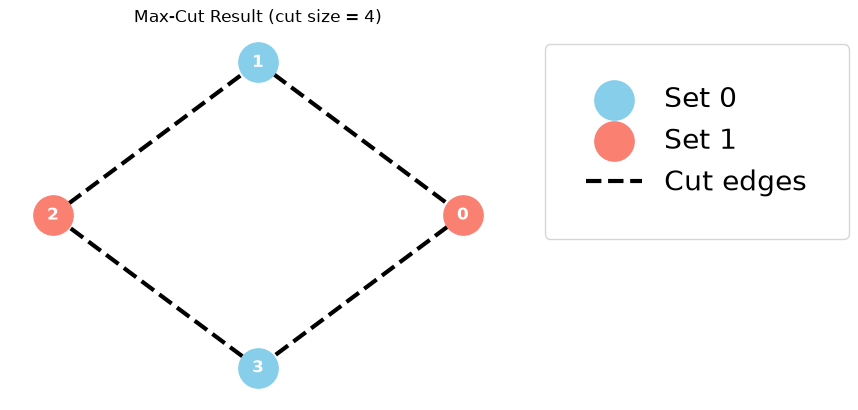

In [8]:
# ---- 6) Display the graph ----------------------------------------------------
G = nx.Graph()
G.add_edges_from(edges)

# Partition nodes into two sets by the bit assignment
partition_0 = [i for i in nodes if x[i] == 0]
partition_1 = [i for i in nodes if x[i] == 1]

# Compute layout for plotting
pos = nx.circular_layout(G)

# Draw nodes by partition color
nx.draw_networkx_nodes(G, pos, nodelist=partition_0, node_color="skyblue", node_size=800, label="Set 0")
nx.draw_networkx_nodes(G, pos, nodelist=partition_1, node_color="salmon", node_size=800, label="Set 1")

# Draw edges: highlight cut edges
cut_edges = [(i, j) for i, j in edges if x[i] != x[j]]
uncut_edges = [(i, j) for i, j in edges if x[i] == x[j]]

nx.draw_networkx_edges(G, pos, edgelist=cut_edges, width=3, edge_color="black", style="dashed", label="Cut edges")
nx.draw_networkx_edges(G, pos, edgelist=uncut_edges, width=1, edge_color="gray")

nx.draw_networkx_labels(G, pos, font_color="white", font_weight="bold")

plt.title(f"Max-Cut Result (cut size = {cut})")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderpad=1.5, scatterpoints=1, fontsize=20)
#plt.legend(scatterpoints=1)
plt.axis("off")
plt.show()
